## 1. Preparação do Ambiente e Importação das Bibliotecas

Nesta célula importamos as bibliotecas essenciais para manipulação de dados (pandas), visualização gráfica (matplotlib), divisão amostral (train_test_split), modelagem de Árvore de Decisão (DecisionTreeClassifier, export_text, plot_tree) e avaliação de desempenho (accuracy_score, confusion_matrix, ConfusionMatrixDisplay).

In [ ]:
# Manipulação e análise de estruturas tabulares (DataFrames)
import pandas as pd

# Geração de gráficos e visualizações da árvore e da matriz de confusão
import matplotlib.pyplot as plt

# Separação estratificada entre conjuntos de treinamento e teste
from sklearn.model_selection import train_test_split

# Algoritmo de Aprendizado Supervisionado (Árvore de Decisão) e utilitários de inspeção
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# Métricas de avaliação do classificador
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Bibliotecas carregadas com sucesso! Ambiente pronto para execução.")

Bibliotecas carregadas com sucesso! Ambiente pronto para execução.


## 2. Dataset Rotulado (Dados Simulados de Qualidade de Bases)

### Especificação da Base de Dados
* Origem: Dados simulados (sintéticos) criados para espelhar métricas reais de Análise Exploratória de Dados (AED).
* Tamanho: $24$ registros perfeitamente balanceados ($12$ exemplos da classe "pronto_para_treino" e $12$ exemplos da classe "requer_tratamento").
* Atributos ($X$):
  * perc_nulos: Percentual médio de valores ausentes (NaN) no dataset ($0.0\%$ a $100.0\%$).
  * desbalanceamento_classes: Percentual de representatividade da classe majoritária ($50.0\%$ = equilibrado; $> 70.0\%$ = desbalanceado).
* Rótulo ($y$) e Critério de Rotulagem:
  * "pronto_para_treino": atribuído quando $\text{perc\_nulos} \le 10.0\%$ E $\text{desbalanceamento\_classes} \le 70.0\%$.
  * "requer_tratamento": atribuído quando qualquer um desses dois limites de qualidade é ultrapassado.

Além de estruturar o DataFrame em memória, o código abaixo salva o arquivo dataset_qualidade_dados.csv no ambiente do Colab para exportação.

In [ ]:
# Criação do DataFrame simulado com métricas de qualidade de datasets
dados = pd.DataFrame({
    "perc_nulos": [
        # 12 casos limpos e equilibrados (pronto_para_treino)
        0.0, 1.5, 2.0, 3.0, 4.5, 5.0, 6.0, 7.5, 8.0, 8.5, 9.0, 9.5,
        # 8 casos com excesso de nulos (> 10%)
        15.0, 18.5, 22.0, 25.0, 30.0, 35.5, 42.0, 50.0,
        # 4 casos com poucos nulos, mas forte desbalanceamento (> 70%)
        4.0, 6.5, 8.0, 12.0
    ],
    "desbalanceamento_classes": [
        50.0, 52.0, 55.0, 58.0, 60.0, 51.0, 62.0, 65.0, 68.0, 54.0, 69.0, 66.0,
        55.0, 60.0, 72.0, 85.0, 65.0, 90.0, 78.0, 92.0,
        82.0, 88.0, 91.0, 80.0
    ],
    "status_dataset": ["pronto_para_treino"] * 12 + ["requer_tratamento"] * 12
})

# Salva o dataset em CSV no ambiente
dados.to_csv("dataset_qualidade_dados.csv", index=False)

print("= DATASET ROTULADO (24 REGISTROS SIMULADOS) =")
print(dados.to_string(index=False))
print("\nDistribuição das classes:")
print(dados["status_dataset"].value_counts())
print("\nArquivo 'dataset_qualidade_dados.csv' exportado com sucesso!")

= DATASET ROTULADO (24 REGISTROS SIMULADOS) =
 perc_nulos  desbalanceamento_classes     status_dataset
        0.0                      50.0 pronto_para_treino
        1.5                      52.0 pronto_para_treino
        2.0                      55.0 pronto_para_treino
        3.0                      58.0 pronto_para_treino
        4.5                      60.0 pronto_para_treino
        5.0                      51.0 pronto_para_treino
        6.0                      62.0 pronto_para_treino
        7.5                      65.0 pronto_para_treino
        8.0                      68.0 pronto_para_treino
        8.5                      54.0 pronto_para_treino
        9.0                      69.0 pronto_para_treino
        9.5                      66.0 pronto_para_treino
       15.0                      55.0  requer_tratamento
       18.5                      60.0  requer_tratamento
       22.0                      72.0  requer_tratamento
       25.0                      85.0  req

## 3. Separação entre Treinamento e Teste

Para avaliar se o modelo realmente aprendeu padrões generalizáveis (e não apenas decorou os exemplos), separamos:
* $X$ (Atributos): perc_nulos e desbalanceamento_classes.
* $y$ (Rótulo): status_dataset (nunca entra em $X$).
* Proporção: $75\%$ para treino ($18$ exemplos) e $25\%$ para teste ($6$ exemplos), usando stratify=y para manter o equilíbrio das classes em ambas as partições e random_state=42 para reprodutibilidade.

In [ ]:
# Separação entre variáveis explicativas (X) e variável alvo/rótulo (y)
X = dados[["perc_nulos", "desbalanceamento_classes"]]
y = dados["status_dataset"]

# Divisão estratificada (75% treino, 25% teste)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Total Treino: {len(X_treino)} registros | Total Teste: {len(X_teste)} registros")
print("\nProporção no Treino:")
print(y_treino.value_counts())
print("\nProporção no Teste:")
print(y_teste.value_counts())

Total Treino: 18 registros | Total Teste: 6 registros

Proporção no Treino:
status_dataset
pronto_para_treino    9
requer_tratamento     9
Name: count, dtype: int64

Proporção no Teste:
status_dataset
pronto_para_treino    3
requer_tratamento     3
Name: count, dtype: int64


## 4. Treinamento e Avaliação do Modelo Supervisionado

Treinamos um classificador DecisionTreeClassifier(max_depth=3, random_state=42) exclusivamente com X_treino e y_treino (.fit()). Em seguida:
1. Geramos previsões no conjunto inédito X_teste (.predict()).
2. Calculamos a Acurácia e exibimos a Matriz de Confusão (linhas = classes reais; colunas = classes previstas).
3. Extraímos em texto (export_text) e graficamente (plot_tree) as condições matemáticas aprendidas automaticamente pelos dados.

### Como ler cada nó da Árvore de Decisão:
* Condição de corte: Pergunta binária sobre um atributo (ex.: perc_nulos <= 10.75). Verdadeiro segue à esquerda; falso segue à direita.
* gini: Índice de impureza de Gini ($\text{Gini} = 1 - \sum p_i^2$). Quando gini = 0.0, o nó é 100% puro.
* samples: Número de exemplos de treino avaliados naquele nó.
* value: Contagem [pronto_para_treino, requer_tratamento] naquele nó.

Acurácia no conjunto de teste: 100.0%

= MATRIZ DE CONFUSÃO (Linhas = Real | Colunas = Previsto) =
                    pronto_para_treino  requer_tratamento
pronto_para_treino                   3                  0
requer_tratamento                    0                  3


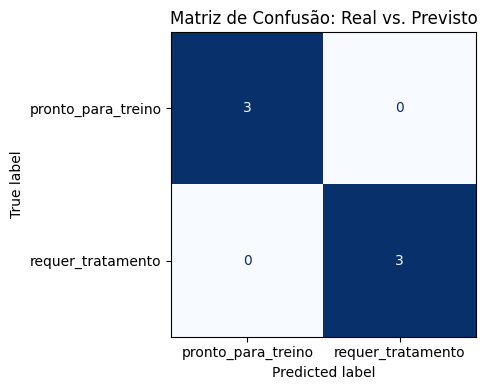


= CONDIÇÕES APRENDIDAS AUTOMATICAMENTE PELA ÁRVORE =
|--- perc_nulos <= 12.25
|   |--- desbalanceamento_classes <= 75.50
|   |   |--- class: pronto_para_treino
|   |--- desbalanceamento_classes >  75.50
|   |   |--- class: requer_tratamento
|--- perc_nulos >  12.25
|   |--- class: requer_tratamento



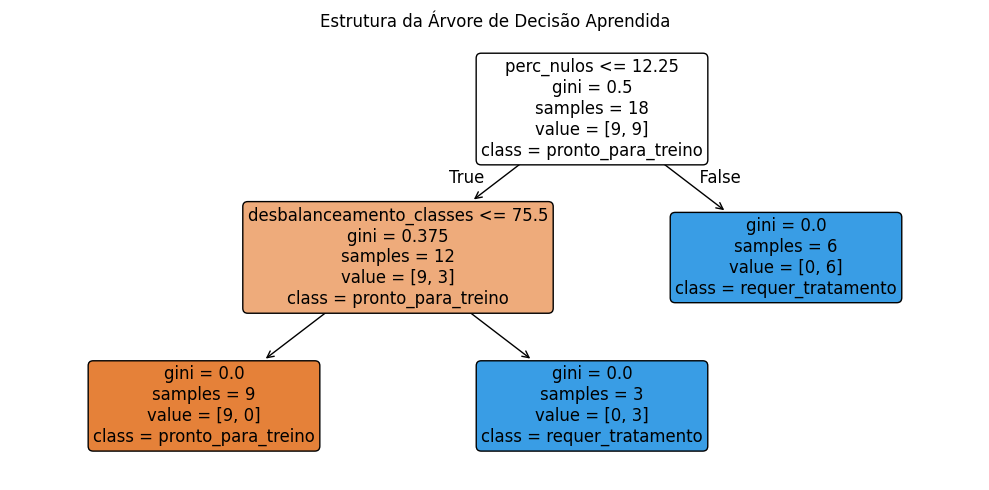

In [ ]:
# Inicialização e treinamento do modelo de Árvore de Decisão
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(X_treino, y_treino)

# Predição no conjunto de teste
previsoes = modelo.predict(X_teste)

# Cálculo da acurácia
acuracia = accuracy_score(y_teste, previsoes)
print(f"Acurácia no conjunto de teste: {acuracia:.1%}")

# Matriz de Confusão
classes = ["pronto_para_treino", "requer_tratamento"]
matriz = confusion_matrix(y_teste, previsoes, labels=classes)
print("\n= MATRIZ DE CONFUSÃO (Linhas = Real | Colunas = Previsto) =")
print(pd.DataFrame(matriz, index=classes, columns=classes))

# Visualização gráfica da Matriz de Confusão
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(matriz, display_labels=classes).plot(cmap="Blues", colorbar=False, ax=ax)
plt.title("Matriz de Confusão: Real vs. Previsto")
plt.tight_layout()
plt.show()

# Regras lógicas induzidas automaticamente a partir dos dados
print("\n= CONDIÇÕES APRENDIDAS AUTOMATICAMENTE PELA ÁRVORE =")
print(export_text(modelo, feature_names=list(X.columns)))

# Visualização gráfica da Árvore de Decisão
plt.figure(figsize=(10, 5))
plot_tree(
    modelo,
    feature_names=list(X.columns),
    class_names=list(modelo.classes_),
    filled=True,
    rounded=True
)
plt.title("Estrutura da Árvore de Decisão Aprendida")
plt.tight_layout()
plt.show()

## 5. Base de Conhecimento e Motor de Inferência (Sistema Especialista)

Aqui implementamos o paradigma da IA Simbólica, separando explicitamente o conhecimento especializado (base_conhecimento) do mecanismo lógico de dedução (motor_inferencia):

* Fato 1 (Dinâmico — vindo do ML): status_dataset ("pronto_para_treino" ou "requer_tratamento").
* Fato 2 (Contextual — informado pelo usuário): volume_pequeno (True se $< 500$ registros; False caso contrário).
* Estratégia: Encadeamento para Frente (Forward Chaining), partindo dos fatos da Memória de Trabalho até disparar a regra correspondente (R1, R2, R3 ou R4) e gerar uma explicação auditável.

In [ ]:
# Base de Conhecimento: Regras de produção SE... ENTÃO... criadas por especialista
base_conhecimento = [
    {
        "id": "R1",
        "status_dataset": "requer_tratamento",
        "volume_pequeno": True,
        "acao": "Aplicar imputação estatística (mediana/moda) nos nulos e oversampling (SMOTE) para balanceamento.",
        "justificativa": "Em datasets pequenos (< 500 linhas), remover registros comprometeria a amostra estatística."
    },
    {
        "id": "R2",
        "status_dataset": "requer_tratamento",
        "volume_pequeno": False,
        "acao": "Remover registros incompletos (dropna) e aplicar undersampling ou ajuste de pesos (class_weight).",
        "justificativa": "Com grande volume de dados, descartar linhas nulas evita ruído sintético mantendo fidelidade."
    },
    {
        "id": "R3",
        "status_dataset": "pronto_para_treino",
        "volume_pequeno": True,
        "acao": "Treinar modelos de baixa complexidade (Árvore rasa ou KNN) com Validação Cruzada (K-Fold).",
        "justificativa": "Bases limpas mas pequenas têm alto risco de overfitting; K-Fold maximiza o uso dos dados."
    },
    {
        "id": "R4",
        "status_dataset": "pronto_para_treino",
        "volume_pequeno": False,
        "acao": "Seguir com divisão padrão treino/teste e testar modelos ensemble (Random Forest / Gradient Boosting).",
        "justificativa": "Alta integridade aliada a grande volume permite explorar algoritmos de maior capacidade preditiva."
    }
]

# Motor de Inferência (Forward Chaining / Encadeamento para Frente)
def motor_inferencia(status_previsto, volume_pequeno):
    # Memória de Trabalho com os fatos do caso atual
    memoria_trabalho = {
        "fato_1_status_dataset": status_previsto,
        "fato_2_volume_pequeno": volume_pequeno
    }

    for regra in base_conhecimento:
        if (regra["status_dataset"] == memoria_trabalho["fato_1_status_dataset"] and
                regra["volume_pequeno"] == memoria_trabalho["fato_2_volume_pequeno"]):
            return {
                "status_previsto_ml": status_previsto,
                "fato_volume_pequeno": volume_pequeno,
                "regra_aplicada": regra["id"],
                "recomendacao": regra["acao"],
                "explicacao": (
                    f"Fatos: status_dataset='{status_previsto}' E volume_pequeno={volume_pequeno} "
                    f"-> Disparou {regra['id']}. Motivo: {regra['justificativa']}"
                )
            }

    raise ValueError("Nenhuma regra compatível encontrada na Base de Conhecimento.")

print(f"Base de Conhecimento carregada com {len(base_conhecimento)} regras e Motor de Inferência pronto!")

Base de Conhecimento carregada com 4 regras e Motor de Inferência pronto!


## 6. Integração Híbrida e Demonstração de Novos Casos

A função diagnosticar_pipeline() unifica todo o fluxo:
1. Validação de domínio: Verifica se perc_nulos $\in [0, 100]$, desbalanceamento $\in [50, 100]$ e volume_pequeno é booleano.
2. Classificação via ML: Obtém o diagnóstico estatístico da Árvore de Decisão.
3. Inferência via Sistema Especialista: Aciona motor_inferencia() para deduzir a recomendação.
4. Controle de Limites (Governança): Verifica se os valores de entrada extrapolam os intervalos observados durante o treinamento (X_treino.min() e X_treino.max()), emitindo um alerta caso estejam fora do domínio conhecido.

### Casos Testados Abaixo:
* Casos 1, 2 e 3: Três cenários inéditos cobrindo diferentes combinações de qualidade e volume.
* Caso 4 (Teste Contrafactual): Mesmas métricas numéricas do Caso 2 (3.5% nulos, 55.0% desbalanceamento), alterando apenas volume_pequeno de False para True para comprovar o papel do Sistema Especialista.
* Caso 5 (Teste de Extrapolação): Dataset com 65.0% de nulos (acima do máximo de 50.0% visto no treino) para demonstrar o alerta de governança.

In [ ]:
# Função integradora completa (ML + Sistema Especialista + Governança)
def diagnosticar_pipeline(perc_nulos, desbalanceamento, volume_pequeno):
    # 1. Validações de integridade das entradas
    if not 0 <= perc_nulos <= 100:
        raise ValueError("Percentual de nulos deve estar entre 0 e 100.")
    if not 50 <= desbalanceamento <= 100:
        raise ValueError("Desbalanceamento (classe majoritária) deve estar entre 50 e 100.")
    if not isinstance(volume_pequeno, bool):
        raise ValueError("O parâmetro 'volume_pequeno' deve ser True ou False.")

    # 2. Formatação do caso para predição pelo modelo supervisionado
    novo_caso = pd.DataFrame([{
        "perc_nulos": perc_nulos,
        "desbalanceamento_classes": desbalanceamento
    }])

    # 3. Classificação (Aprendizado Supervisionado)
    status_previsto = modelo.predict(novo_caso)[0]

    # 4. Inferência Lógica (Sistema Especialista)
    resultado = motor_inferencia(status_previsto, volume_pequeno)

    # 5. Verificação de extrapolação fora do intervalo observado no treino
    fora_dominio = any(
        not X_treino[col].min() <= novo_caso[col].iloc[0] <= X_treino[col].max()
        for col in X.columns
    )

    resultado["aviso"] = (
        "ALERTA: Entrada fora dos intervalos observados no treino (extrapolação de domínio)."
        if fora_dominio
        else "Caso dentro dos intervalos de treino; recomendação sujeita à revisão humana do cientista de dados."
    )
    return resultado

# Execução da bateria de testes
print("")
print("EXECUÇÃO DOS CASOS DE TESTE - SISTEMA ESPECIALISTA HÍBRIDO")
print("==")

casos_teste = [
    ("Novo Caso - Crítico Pequeno", 28.0, 88.0, True),
    ("Novo Caso - Ideal Grande", 3.5, 55.0, False),
    ("Novo Caso - Crítico Grande", 22.0, 75.0, False),
    ("Comparativo - Muda só Fato", 3.5, 55.0, True),
    ("Governança - Fora de Escopo", 65.0, 95.0, True)
]

for idx, (descricao, nulos, desbal, vol_peq) in enumerate(casos_teste, 1):
    print(f"\nCASO {idx} [{descricao}]: nulos={nulos}% | desbalanceamento={desbal}% | volume_pequeno={vol_peq}")
    saida = diagnosticar_pipeline(nulos, desbal, vol_peq)
    for campo, valor in saida.items():
        print(f"  {campo}: {valor}")


EXECUÇÃO DOS CASOS DE TESTE - SISTEMA ESPECIALISTA HÍBRIDO
==

CASO 1 [Novo Caso - Crítico Pequeno]: nulos=28.0% | desbalanceamento=88.0% | volume_pequeno=True
  status_previsto_ml: requer_tratamento
  fato_volume_pequeno: True
  regra_aplicada: R1
  recomendacao: Aplicar imputação estatística (mediana/moda) nos nulos e oversampling (SMOTE) para balanceamento.
  explicacao: Fatos: status_dataset='requer_tratamento' E volume_pequeno=True -> Disparou R1. Motivo: Em datasets pequenos (< 500 linhas), remover registros comprometeria a amostra estatística.
  aviso: Caso dentro dos intervalos de treino; recomendação sujeita à revisão humana do cientista de dados.

CASO 2 [Novo Caso - Ideal Grande]: nulos=3.5% | desbalanceamento=55.0% | volume_pequeno=False
  status_previsto_ml: pronto_para_treino
  fato_volume_pequeno: False
  regra_aplicada: R4
  recomendacao: Seguir com divisão padrão treino/teste e testar modelos ensemble (Random Forest / Gradient Boosting).
  explicacao: Fatos: status_da

## 7. Análise Crítica, Limitações e Respostas de Fechamento

### Limitações e Cuidados Éticos
* Tamanho da Amostra: O dataset possui $24$ exemplos simulados ($18$ treino / $6$ teste). Um acerto de $100\%$ nesse conjunto não garante eficácia em bases reais ruidosas.
* Qualidade das Métricas (Garbage In, Garbage Out): Valores nulos mascarados (como "N/A" ou -999) precisam ser padronizados antes da extração das métricas.
* Rigidez das Regras: Regras booleanas não tratam zonas intermediárias (o que motivaria o uso futuro de Lógica Fuzzy). Além disso, decisões de exclusão de registros (dropna) exigem revisão humana e conformidade com a LGPD.

### Síntese das Perguntas da Aula
1. O que aprende com os dados? O DecisionTreeClassifier, via .fit(X_treino, y_treino).
2. O que aplica regras humanas? A base_conhecimento e o motor_inferencia (SE... ENTÃO...).
3. Por que volume_pequeno não está em $X$? Porque o ML avalia a qualidade intrínseca dos dados, enquanto o volume é uma restrição operacional avaliada pelo Sistema Especialista.
4. O que muda ao alterar apenas volume_pequeno? A previsão do ML permanece igual (pronto_para_treino), mas a regra acionada muda de R4 para R3 (Caso 2 vs. Caso 4).